In [1]:
!pip -q install wfdb

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb

from scipy.signal import butter, sosfiltfilt
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [3]:
DATA_DIR = "/content/mitbih"
os.makedirs(DATA_DIR, exist_ok=True)

records = wfdb.get_record_list("mitdb")

print("Total available records:", len(records))

for record in records:
    try:
        wfdb.dl_database(
            "mitdb",
            dl_dir=DATA_DIR,
            records=[record]
        )
    except Exception as e:
        print("Download failed:", record, e)

downloaded_records = [
    r for r in records
    if os.path.exists(os.path.join(DATA_DIR, r + ".hea"))
]

print("Successfully downloaded:", len(downloaded_records))
print(downloaded_records)

Total available records: 48
Generating record list for: 100
Generating list of all files for: 100
Finished downloading files
Generating record list for: 101
Generating list of all files for: 101
Finished downloading files
Generating record list for: 102
Generating list of all files for: 102
Finished downloading files
Generating record list for: 103
Generating list of all files for: 103
Finished downloading files
Generating record list for: 104
Generating list of all files for: 104
Finished downloading files
Generating record list for: 105
Generating list of all files for: 105
Finished downloading files
Generating record list for: 106
Generating list of all files for: 106
Finished downloading files
Generating record list for: 107
Generating list of all files for: 107
Finished downloading files
Generating record list for: 108
Generating list of all files for: 108
Finished downloading files
Generating record list for: 109
Generating list of all files for: 109
Finished downloading files
Ge

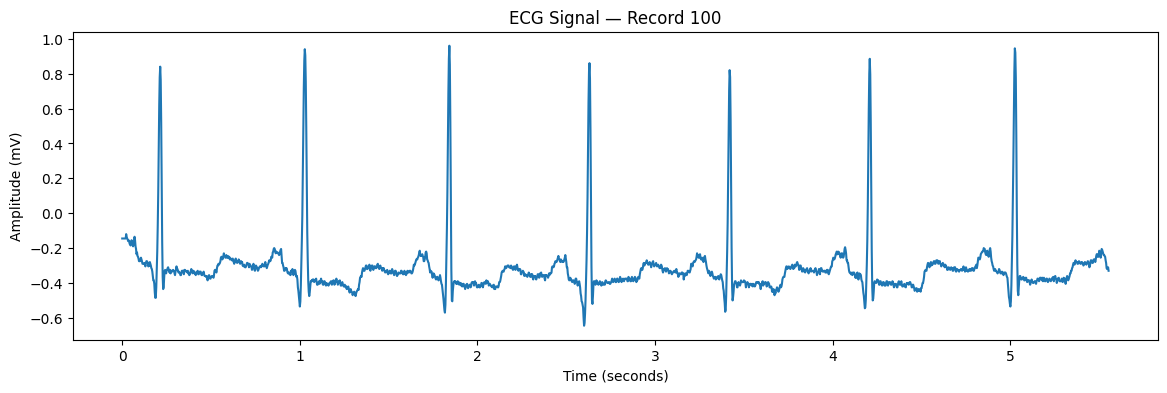

Sampling frequency: 360 Hz
Signal shape: (650000, 2)
Channels: ['MLII', 'V5']


In [4]:
# Commonly excluded paced recordings
paced_records = {"102", "104", "107", "217"}
usable_records = [
    r for r in downloaded_records if r not in paced_records
]

record = usable_records[0]
signal, fields = wfdb.rdsamp(os.path.join(DATA_DIR, record))

plt.figure(figsize=(14, 4))
plt.plot(np.arange(2000) / fields["fs"], signal[:2000, 0])
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title(f"ECG Signal — Record {record}")
plt.show()

print("Sampling frequency:", fields["fs"], "Hz")
print("Signal shape:", signal.shape)
print("Channels:", fields["sig_name"])

Beat tensor shape: (100715, 144)
Labels shape: (100715,)
Records represented: 44

AAMI class distribution:
N    90109
S     2781
V     7008
F      802
Q       15
Name: count, dtype: int64


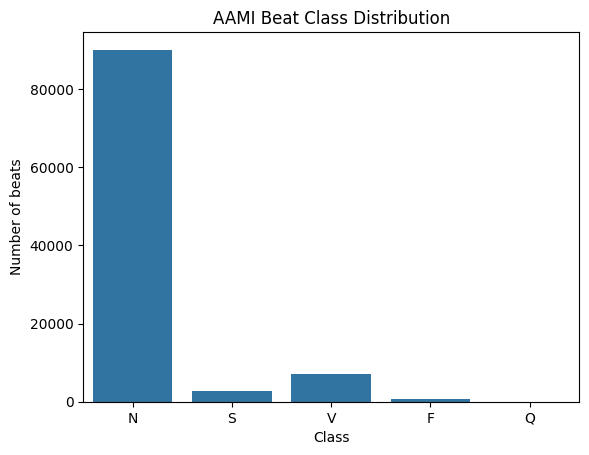

In [5]:
FS = 360
BEFORE = int(0.2 * FS)
AFTER = int(0.2 * FS)
WINDOW = BEFORE + AFTER
AAMI_CLASSES = ["N", "S", "V", "F", "Q"]

# AAMI beat annotation mapping
AAMI_MAP = {
    **{s: "N" for s in ["N", "L", "R", "e", "j"]},
    **{s: "S" for s in ["A", "a", "J", "S"]},
    **{s: "V" for s in ["V", "E"]},
    "F": "F",
    **{s: "Q" for s in ["/", "f", "Q"]}
}

sos = butter(
    4, [0.5, 40], btype="bandpass", fs=FS, output="sos"
)

beats = []
labels = []
beat_records = []

for record in usable_records:
    try:
        signal, fields = wfdb.rdsamp(os.path.join(DATA_DIR, record))
        annotation = wfdb.rdann(
            os.path.join(DATA_DIR, record), "atr"
        )

        # Use first ECG channel
        ecg = signal[:, 0]
        filtered = sosfiltfilt(sos, ecg)

        for sample, symbol in zip(
            annotation.sample, annotation.symbol
        ):
            if symbol not in AAMI_MAP:
                continue

            start = sample - BEFORE
            end = sample + AFTER

            if start < 0 or end > len(filtered):
                continue

            beat = filtered[start:end].astype(np.float32)

            # Normalize each beat
            beat = (beat - beat.mean()) / (beat.std() + 1e-8)

            beats.append(beat)
            labels.append(AAMI_MAP[symbol])
            beat_records.append(record)

    except Exception as e:
        print("Skipped record:", record, e)

X = np.array(beats, dtype=np.float32)
y = np.array(labels)
groups = np.array(beat_records)

print("Beat tensor shape:", X.shape)
print("Labels shape:", y.shape)
print("Records represented:", len(np.unique(groups)))

print("\nAAMI class distribution:")
print(pd.Series(y).value_counts().reindex(AAMI_CLASSES, fill_value=0))

sns.countplot(x=y, order=AAMI_CLASSES)
plt.title("AAMI Beat Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of beats")
plt.show()

In [6]:
unique_records = np.unique(groups)

train_records, temp_records = train_test_split(
    unique_records, test_size=0.30, random_state=SEED
)

val_records, test_records = train_test_split(
    temp_records, test_size=0.50, random_state=SEED
)

train_mask = np.isin(groups, train_records)
val_mask = np.isin(groups, val_records)
test_mask = np.isin(groups, test_records)

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Train:", X_train.shape, "Records:", len(train_records))
print("Validation:", X_val.shape, "Records:", len(val_records))
print("Test:", X_test.shape, "Records:", len(test_records))

print("Train classes:", pd.Series(y_train).value_counts().to_dict())
print("Validation classes:", pd.Series(y_val).value_counts().to_dict())
print("Test classes:", pd.Series(y_test).value_counts().to_dict())

Train: (68529, 144) Records: 30
Validation: (15774, 144) Records: 7
Test: (16412, 144) Records: 7
Train classes: {'N': 60635, 'V': 5240, 'S': 1877, 'F': 769, 'Q': 8}
Validation classes: {'N': 14633, 'V': 785, 'S': 338, 'F': 18}
Test classes: {'N': 14841, 'V': 983, 'S': 566, 'F': 15, 'Q': 7}


In [7]:
class_to_id = {name: i for i, name in enumerate(AAMI_CLASSES)}

y_train_id = np.array([class_to_id[v] for v in y_train])
y_val_id = np.array([class_to_id[v] for v in y_val])
y_test_id = np.array([class_to_id[v] for v in y_test])

present_classes = np.unique(y_train_id)

weights = compute_class_weight(
    class_weight="balanced",
    classes=present_classes,
    y=y_train_id
)

class_weights = {
    int(c): float(w) for c, w in zip(present_classes, weights)
}

# Add the singleton channel dimension for recurrent models
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Input shape:", X_train.shape)
print("Class weights:", class_weights)

Input shape: (68529, 144, 1)
Class weights: {0: 0.22603776696627362, 1: 7.301971230687267, 2: 2.6156106870229006, 3: 17.822886866059818, 4: 1713.225}


In [8]:
def build_model(model_type):
    inputs = layers.Input(shape=(WINDOW, 1))

    if model_type == "RNN":
        x = layers.SimpleRNN(64)(inputs)
    elif model_type == "LSTM":
        x = layers.LSTM(64)(inputs)
    elif model_type == "GRU":
        x = layers.GRU(64)(inputs)

    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(len(AAMI_CLASSES), activation="softmax")(x)

    model = models.Model(inputs, outputs)

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [9]:
trained_models = {}
histories = {}

for model_type in ["RNN", "LSTM", "GRU"]:
    print(f"\nTraining {model_type}...")

    model = build_model(model_type)

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    history = model.fit(
        X_train, y_train_id,
        validation_data=(X_val, y_val_id),
        epochs=15,
        batch_size=128,
        class_weight=class_weights,
        callbacks=[early_stop],
        verbose=1
    )

    trained_models[model_type] = model
    histories[model_type] = history


Training RNN...
Epoch 1/15
536/536 ━━━━━━━━━━━━━━━━━━━━ 24s 43ms/step - accuracy: 0.1883 - loss: 1.5414 - val_accuracy: 0.4074 - val_loss: 1.2423
Epoch 2/15
536/536 ━━━━━━━━━━━━━━━━━━━━ 39s 39ms/step - accuracy: 0.3007 - loss: 1.4464 - val_accuracy: 0.3242 - val_loss: 1.3946
Epoch 3/15
536/536 ━━━━━━━━━━━━━━━━━━━━ 21s 39ms/step - accuracy: 0.1956 - loss: 1.7027 - val_accuracy: 0.0119 - val_loss: 1.5204
Epoch 4/15
536/536 ━━━━━━━━━━━━━━━━━━━━ 21s 39ms/step - accuracy: 0.1518 - loss: 1.7189 - val_accuracy: 0.0235 - val_loss: 1.5481

Training LSTM...
Epoch 1/15
536/536 ━━━━━━━━━━━━━━━━━━━━ 100s 183ms/step - accuracy: 0.0958 - loss: 1.6334 - val_accuracy: 0.0233 - val_loss: 1.5241
Epoch 2/15
536/536 ━━━━━━━━━━━━━━━━━━━━ 98s 183ms/step - accuracy: 0.1975 - loss: 1.3578 - val_accuracy: 0.4024 - val_loss: 1.2897
Epoch 3/15
536/536 ━━━━━━━━━━━━━━━━━━━━ 98s 183ms/step - accuracy: 0.2218 - loss: 1.3484 - val_accuracy: 0.1590 - val_loss: 1.5807
Epoch 4/15
536/536 ━━━━━━━━━━━━━━━━━━━━ 98s 183ms/s


RNN Classification Report
              precision    recall  f1-score   support

           N       0.51      0.01      0.03     14841
           S       0.07      0.72      0.12       566
           V       0.08      0.00      0.00       983
           F       0.00      0.93      0.00        15
           Q       0.33      0.14      0.20         7

    accuracy                           0.04     16412
   macro avg       0.20      0.36      0.07     16412
weighted avg       0.47      0.04      0.03     16412



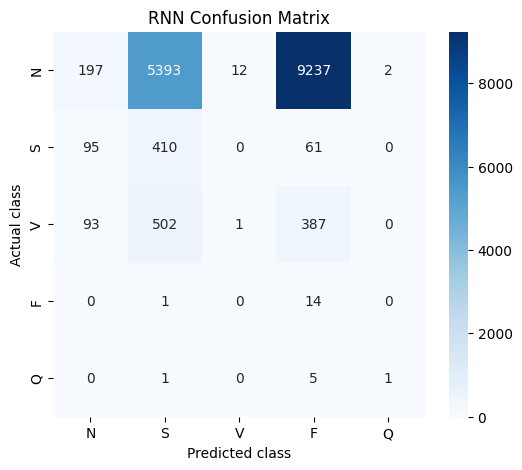


LSTM Classification Report
              precision    recall  f1-score   support

           N       0.94      0.61      0.74     14841
           S       0.01      0.02      0.01       566
           V       0.14      0.28      0.19       983
           F       0.00      0.00      0.00        15
           Q       0.00      0.14      0.00         7

    accuracy                           0.57     16412
   macro avg       0.22      0.21      0.19     16412
weighted avg       0.85      0.57      0.68     16412



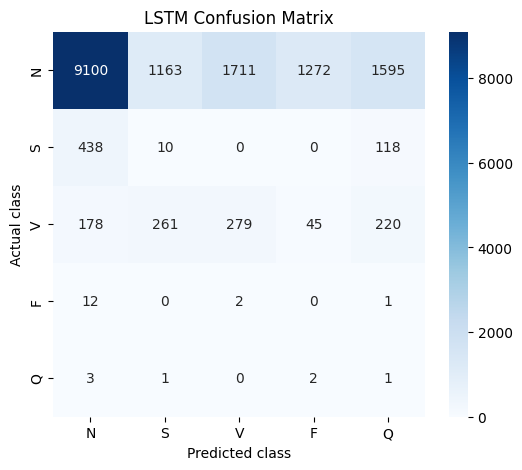


GRU Classification Report
              precision    recall  f1-score   support

           N       0.92      0.60      0.73     14841
           S       0.03      0.07      0.04       566
           V       0.18      0.40      0.25       983
           F       0.00      0.13      0.00        15
           Q       0.00      0.14      0.00         7

    accuracy                           0.57     16412
   macro avg       0.23      0.27      0.21     16412
weighted avg       0.85      0.57      0.67     16412



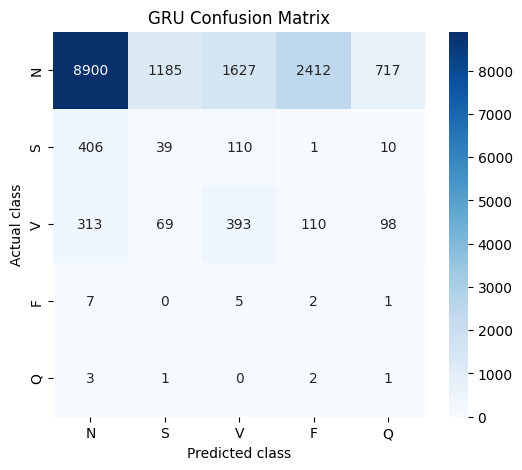

,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
RNN,0.0380,0.1977,0.3630,0.0700
LSTM,0.5721,0.2165,0.2115,0.1879
GRU,0.5688,0.2281,0.2689,0.2051


In [10]:
results = []

for model_type, model in trained_models.items():
    probabilities = model.predict(X_test, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    results.append({
        "Model": model_type,
        "Accuracy": accuracy_score(y_test_id, predictions),
        "Precision (macro)": precision_score(
            y_test_id, predictions, average="macro", zero_division=0
        ),
        "Recall (macro)": recall_score(
            y_test_id, predictions, average="macro", zero_division=0
        ),
        "F1-score (macro)": f1_score(
            y_test_id, predictions, average="macro", zero_division=0
        )
    })

    print(f"\n{model_type} Classification Report")
    print(classification_report(
        y_test_id,
        predictions,
        labels=list(range(len(AAMI_CLASSES))),
        target_names=AAMI_CLASSES,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_test_id,
        predictions,
        labels=list(range(len(AAMI_CLASSES)))
    )

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=AAMI_CLASSES,
        yticklabels=AAMI_CLASSES
    )
    plt.xlabel("Predicted class")
    plt.ylabel("Actual class")
    plt.title(f"{model_type} Confusion Matrix")
    plt.show()

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))

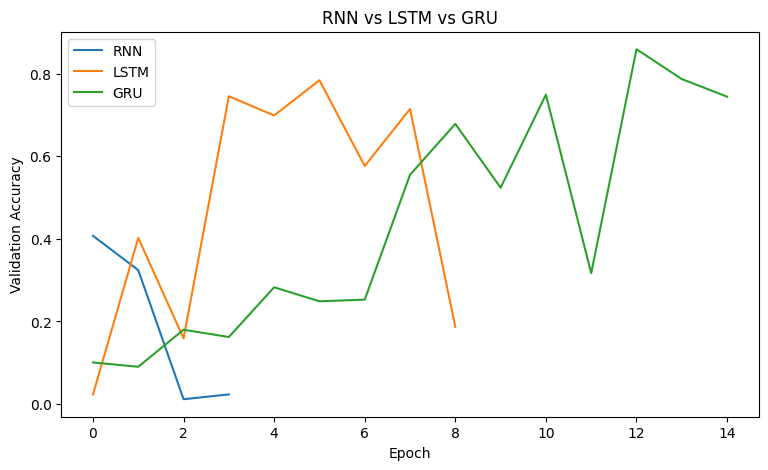

In [11]:
plt.figure(figsize=(9, 5))

for model_type, history in histories.items():
    plt.plot(history.history["val_accuracy"], label=model_type)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("RNN vs LSTM vs GRU")
plt.legend()
plt.show()